# 01 · RQ1: Price/Performance Tiers of the LLM API Market
**Project:** Classifying the 2026 LLM API Market · ICT324 · Team Straw Hats · CRISP-DM phase: *Modeling (clustering)*

### Research question and hypothesis
> **RQ1:** What price/performance tiers exist in the LLM API market?
>
> **H1:** The market forms **at least 3 distinct tiers**, including **one with a high price but no matching benchmark advantage**.

### Method in one picture
```
clean data (notebook 00)
  → features: log price  +  composite performance score
  → standardize
  → STEP A  Hierarchical clustering (Ward): dendrogram + metrics  → choose best k
  → STEP B  K-means with that k                                   → final tiers
  → check agreement & stability  → profile tiers  → test H1 statistically
```
Why two methods? **Hierarchical clustering** does not need k in advance. Its dendrogram shows the whole merge history, which makes it a good tool for *choosing* k. **K-means** gives compact, centroid-based clusters that are easy to explain and to apply to new models (RQ2). If both methods give similar tiers, the tiers are a property of the data, not an artefact of one algorithm.

### How to run in Google Colab
Run the cells in order. The setup cell asks you to upload `clean_models.csv` and `clean_benchmarks.csv`, which are outputs of notebook 00 (inside `clean_data.zip`).

## Step 1 · Setup
Libraries (all preinstalled on Colab) and one fixed random seed, so every run gives the same result.

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import kruskal, mannwhitneyu
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
SEED = 42
K_RANGE = range(2, 9)          # candidate numbers of tiers
MIN_MODELS_PER_TEST = 5        # a benchmark must cover ≥5 models to be used

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import files
    DATA_DIR, OUT_DIR = ".", "."
    need = ["clean_models.csv", "clean_benchmarks.csv"]
    if not all(os.path.exists(f) for f in need):
        print("Upload clean_models.csv and clean_benchmarks.csv (from notebook 00):")
        files.upload()
else:
    DATA_DIR = OUT_DIR = "../data/processed"

models = pd.read_csv(os.path.join(DATA_DIR, "clean_models.csv"))
bench = pd.read_csv(os.path.join(DATA_DIR, "clean_benchmarks.csv"))
print("models:", models.shape, "| benchmark rows:", bench.shape)

models: (411, 33) | benchmark rows: (977, 16)


## Step 2 · Choose the models to cluster
A model can be placed on a price/performance map only if it has **both**:
1. a **valid price**: `has_valid_price` from notebook 00 (median price across providers > 0), and
2. at least one score on a **well-covered benchmark test**. A *test* is one (benchmark, metric) pair, and it counts as well covered when **≥ 5** of these priced models have a score on it. With fewer models, a "rank within the test" means little.

We use only *higher-is-better* metrics, so that ranks always point the same way.

In [2]:
priced = models[models.has_valid_price].copy()
b = bench[bench.higher_is_better & bench.model_id.isin(priced.model_id)].copy()
b["test"] = b.benchmark_clean + " [" + b.metric_clean + "]"

cover = b.groupby("test").model_id.nunique()
good_tests = cover[cover >= MIN_MODELS_PER_TEST].index
b = b[b.test.isin(good_tests)]
pop = priced[priced.model_id.isin(b.model_id)].copy()

print(f"text LLMs: {len(models)}  →  with valid price: {len(priced)}  →  "
      f"with ≥1 well-covered test: {len(pop)}")
print(f"well-covered tests used: {len(good_tests)}")
print(cover[cover >= MIN_MODELS_PER_TEST].sort_values(ascending=False).head(10).to_string())

text LLMs: 411  →  with valid price: 356  →  with ≥1 well-covered test: 144
well-covered tests used: 43
test
SWE-Bench Pro [resolve rate]                43
SWE-Bench Verified [resolved]               34
Aider Polyglot [percent correct]            29
SciCode [percent correct]                   27
Artificial Analysis Coding Index [index]    26
Terminal-Bench [success rate]               24
Humanity's Last Exam [accuracy]             23
Terminal-Bench Hard [success rate]          22
GDPval-AA [elo]                             21
GPQA Diamond [accuracy]                     19


## Step 3 · Build one comparable **performance score**
Benchmarks use different units: % accuracy, Elo, index points. Each model is also tested on a *different* small set of benchmarks (notebook 00 showed the coverage matrix is only about 12% filled). So raw scores cannot be averaged.

**Solution: percentile rank within each test, then average.**
1. Within each test, rank the models and scale the rank to **0 (worst) … 1 (best)**: `(rank − 1) / (n − 1)`. Ties share a rank.
2. A model's **performance score** is the **mean** of its percentiles over all its tests.
3. We also keep `n_tests`, the number of tests behind the score. A score based on 1 test is less reliable than one based on 10. Step 11 checks the results with only multi-test models.

*Example:* a model that ranks 2nd of 11 on SWE-Bench Pro gets (10 − 1)/(11 − 1) = 0.9 on that test.

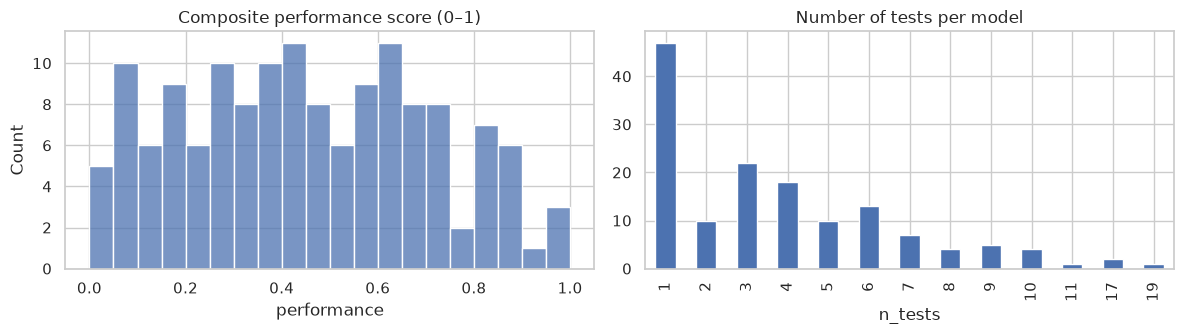

count    144.000
mean       0.449
std        0.255
min        0.000
25%        0.253
50%        0.430
75%        0.638
max        1.000


In [3]:
def percentile_within_test(df):
    r = df.groupby("test")["score"].rank(method="average")
    n = df.groupby("test")["score"].transform("size")
    return (r - 1) / (n - 1)

b["pctl"] = percentile_within_test(b)
perf = b.groupby("model_id").agg(performance=("pctl", "mean"), n_tests=("pctl", "size"))
pop = pop.merge(perf, left_on="model_id", right_index=True)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(pop.performance, bins=20, ax=ax[0]); ax[0].set_title("Composite performance score (0–1)")
pop.n_tests.value_counts().sort_index().plot.bar(ax=ax[1]); ax[1].set_title("Number of tests per model")
plt.tight_layout(); plt.show()
print(pop.performance.describe().round(3).to_string())

**Reading the plots:** the scores spread over the whole 0–1 range, so the measure separates models well. Many models rest on only 1–3 tests, which is why Step 11 re-runs the analysis on the better-supported models.

## Step 4 · Build one **price** number
Each model has an input price and an output price (USD per 1M tokens). Typical workloads send more input than they get back, so we use the common **3 : 1 blended price**:

$$\text{blended} = \frac{3 \cdot \text{input} + 1 \cdot \text{output}}{4}$$

We use the **median across providers** (from notebook 00) rather than the minimum, because minimums are often temporary free or promo listings.

Prices span about **four orders of magnitude** (cents to over $50). On a linear scale, a few very expensive models would dominate every distance calculation, so we cluster on **log10(price)**. On that scale "10× more expensive" is the same distance anywhere on the axis.

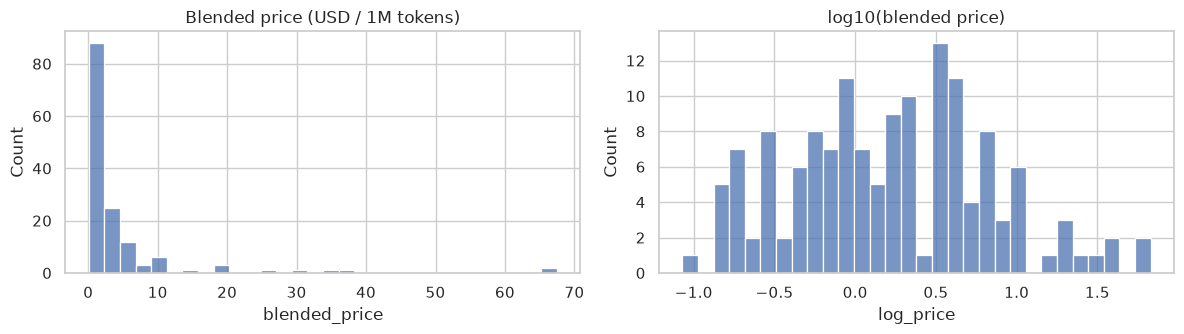

count    144.000
mean       4.583
std        9.672
min        0.085
25%        0.525
50%        1.688
75%        4.375
max       67.500


In [4]:
pop["blended_price"] = (3 * pop.median_input_price_per_1m + pop.median_output_price_per_1m) / 4
pop["log_price"] = np.log10(pop.blended_price)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(pop.blended_price, bins=30, ax=ax[0]); ax[0].set_title("Blended price (USD / 1M tokens)")
sns.histplot(pop.log_price, bins=30, ax=ax[1]); ax[1].set_title("log10(blended price)")
plt.tight_layout(); plt.show()
print(pop.blended_price.describe().round(3).to_string())

**Reading the plots:** the raw price is heavily right-skewed, with a long tail of premium models. After the log transform the distribution is far more symmetric, which suits distance-based clustering.

## Step 5 · Feature matrix and standardization
We cluster on exactly **two features**: `log_price` and `performance`. Two features keep the tiers easy to explain ("cheap and strong", "expensive but average"…) and let us *see* every cluster in a 2-D plot.

The two features have different spreads, so we **standardize** each one to mean 0 and standard deviation 1. Otherwise the feature with the larger numeric range would dominate the distances.

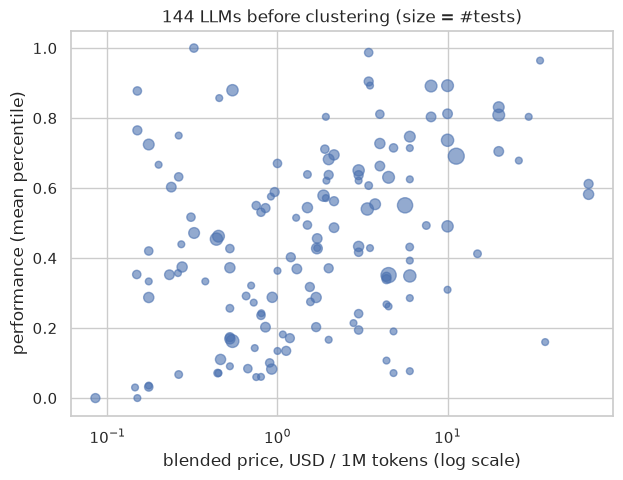

standardized means: [ 0. -0.] | std: [1. 1.]


In [5]:
FEATURES = ["log_price", "performance"]
X = StandardScaler().fit_transform(pop[FEATURES])

plt.figure(figsize=(7, 5))
plt.scatter(pop.blended_price, pop.performance, s=18 + 6 * pop.n_tests, alpha=.6)
plt.xscale("log"); plt.xlabel("blended price, USD / 1M tokens (log scale)")
plt.ylabel("performance (mean percentile)"); plt.title(f"{len(pop)} LLMs before clustering (size = #tests)")
plt.show()
print("standardized means:", X.mean(0).round(3), "| std:", X.std(0).round(3))

**Reading the plot:** price and performance are positively related (better models cost more), but the cloud is wide. At any given price level, performance varies a lot. That spread is exactly what tiers should capture.

## Step 6 · STEP A: Hierarchical clustering to find the best k
**How it works (agglomerative, Ward linkage).** Every model starts as its own cluster. At each step the two clusters whose merge increases the **within-cluster variance** the least are joined, until a single cluster remains. Ward linkage suits our goal: it produces compact, similar-sized groups, which matches what K-means will later optimize.

### 6a · Dendrogram
The y-axis shows the **merge distance**, the cost of joining two clusters. A **long vertical gap** means the clusters below it are well separated. Cutting the tree inside the biggest gap gives a natural number of clusters.

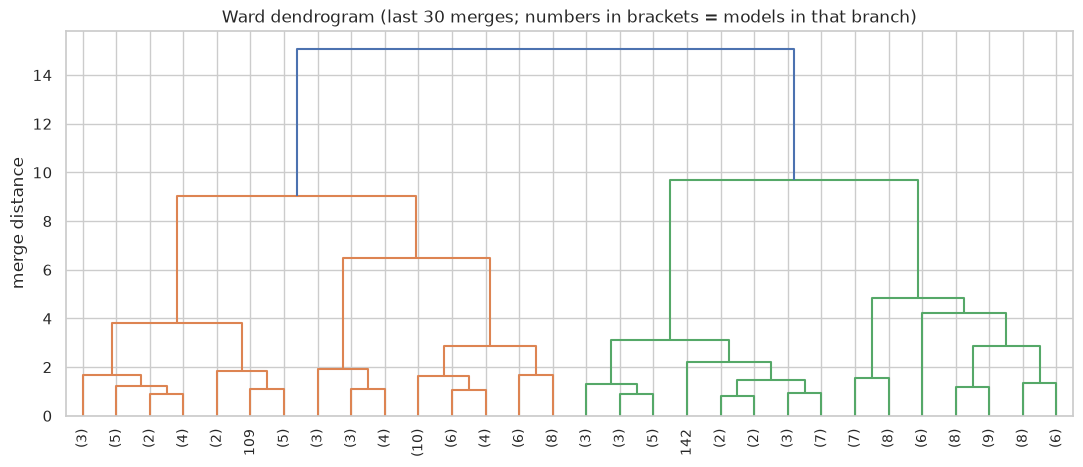

In [6]:
Z = linkage(X, method="ward")
plt.figure(figsize=(13, 5))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90,
           color_threshold=None)
plt.title("Ward dendrogram (last 30 merges; numbers in brackets = models in that branch)")
plt.ylabel("merge distance"); plt.show()

### 6b · Merge-distance "elbow"
The dendrogram is easier to read as numbers. We plot the distance of the last merges. Going from **k clusters to k − 1**, the jump in distance shows how costly that merge is. A **large jump** means two well-separated groups would be forced together, so k is a good place to stop.

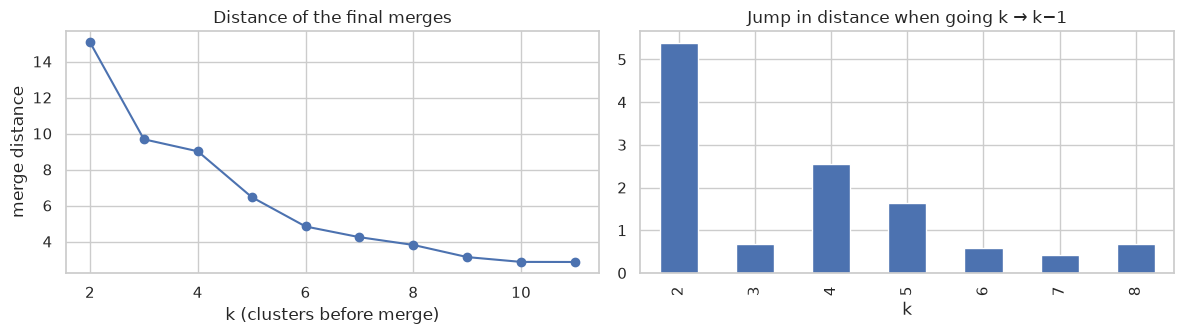

largest jumps: {2: 5.39, 4: 2.54, 5: 1.63}


In [7]:
last = Z[-10:, 2][::-1]                     # distances of the final 10 merges
ks = np.arange(1, len(last) + 1)            # number of clusters *before* each of these merges → k = 2..11
gaps = pd.Series(last[:-1] - last[1:], index=ks[1:])   # jump when going from k to k-1
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(ks + 1, last, "o-"); ax[0].set_xlabel("k (clusters before merge)"); ax[0].set_ylabel("merge distance")
ax[0].set_title("Distance of the final merges")
gaps.loc[list(K_RANGE)].plot.bar(ax=ax[1]); ax[1].set_title("Jump in distance when going k → k−1")
ax[1].set_xlabel("k"); plt.tight_layout(); plt.show()
print("largest jumps:", gaps.loc[list(K_RANGE)].sort_values(ascending=False).round(2).head(3).to_dict())

### 6c · Internal validity metrics for each k
The dendrogram gives a visual hint. Three standard metrics make the choice objective. We cut the Ward tree at every k from 2 to 8 and score each cut:

| Metric | Measures | Better |
|---|---|---|
| **Silhouette** (−1…1) | how much closer each model is to its own cluster than to the nearest other cluster | higher |
| **Davies–Bouldin** (≥0) | average similarity between each cluster and its most similar neighbour | lower |
| **Calinski–Harabasz** | between-cluster vs within-cluster variance | higher |

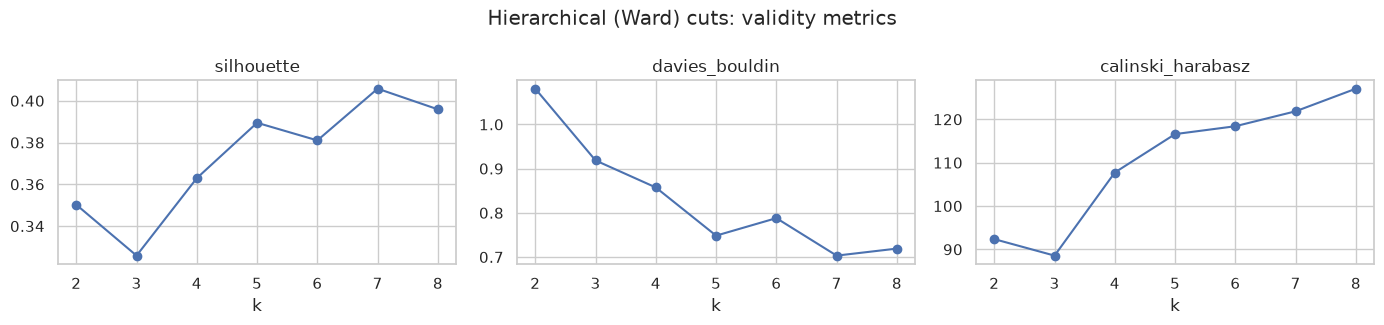

,silhouette,davies_bouldin,calinski_harabasz
k,,,
2,0.350,1.081,92.363
3,0.326,0.918,88.559
4,0.363,0.857,107.731
5,0.389,0.748,116.589
6,0.381,0.788,118.405
7,0.406,0.703,121.851
8,0.396,0.719,127.067


In [8]:
def score_labels(X, labels):
    return {"silhouette": silhouette_score(X, labels),
            "davies_bouldin": davies_bouldin_score(X, labels),
            "calinski_harabasz": calinski_harabasz_score(X, labels)}

hc_scores = pd.DataFrame({k: score_labels(X, AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X))
                          for k in K_RANGE}).T
hc_scores.index.name = "k"

fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
for a, col in zip(ax, hc_scores.columns):
    a.plot(hc_scores.index, hc_scores[col], "o-"); a.set_title(col); a.set_xlabel("k")
plt.suptitle("Hierarchical (Ward) cuts: validity metrics"); plt.tight_layout(); plt.show()
hc_scores.round(3)

### 6d · Decide k
The metrics rarely agree perfectly, so we use a **transparent voting rule**. Each k gets a rank on each metric (1 = best), and the k with the **best average rank** wins. Ties are broken by silhouette. The rule allows k = 2 as well, so the test of H1 ("at least 3 tiers") is not decided in advance.

In [9]:
ranks = pd.DataFrame({
    "silhouette": hc_scores.silhouette.rank(ascending=False),
    "davies_bouldin": hc_scores.davies_bouldin.rank(ascending=True),
    "calinski_harabasz": hc_scores.calinski_harabasz.rank(ascending=False),
})
ranks["mean_rank"] = ranks.mean(axis=1)
ranks["gap_rank"] = gaps.loc[list(K_RANGE)].rank(ascending=False)    # shown for reference
best = ranks.assign(sil=hc_scores.silhouette).sort_values(["mean_rank", "sil"], ascending=[True, False])
BEST_K = int(best.index[0])
display(best.drop(columns="sil").round(2))
print(f"→ Best k from hierarchical clustering: k = {BEST_K} "
      f"(silhouette {hc_scores.silhouette[BEST_K]:.3f}, DB {hc_scores.davies_bouldin[BEST_K]:.3f})")
hc_labels = AgglomerativeClustering(n_clusters=BEST_K, linkage="ward").fit_predict(X)

,silhouette,davies_bouldin,calinski_harabasz,mean_rank,gap_rank
k,,,,,
7,1.0,1.0,2.0,1.33,7.0
8,2.0,2.0,1.0,1.67,4.0
5,3.0,3.0,4.0,3.33,3.0
6,4.0,4.0,3.0,3.67,6.0
4,5.0,5.0,5.0,5.00,2.0
2,6.0,7.0,6.0,6.33,1.0
3,7.0,6.0,7.0,6.67,5.0


→ Best k from hierarchical clustering: k = 7 (silhouette 0.406, DB 0.703)


## Step 7 · STEP B: K-means with the chosen k
**How it works.** K-means places k centroids and repeats two steps: assign each model to its nearest centroid, then move each centroid to the mean of its models. It stops when nothing changes. The result depends on the starting centroids, so we use `n_init = 50`: 50 different starts, keeping the best one.

### 7a · Cross-check: does K-means agree on k?
Before fitting the final model, we compute K-means' own **elbow** (inertia, the within-cluster sum of squares) and **silhouette** for k = 2–8. If K-means also favours the k chosen in Step 6, the choice of k holds for both methods.

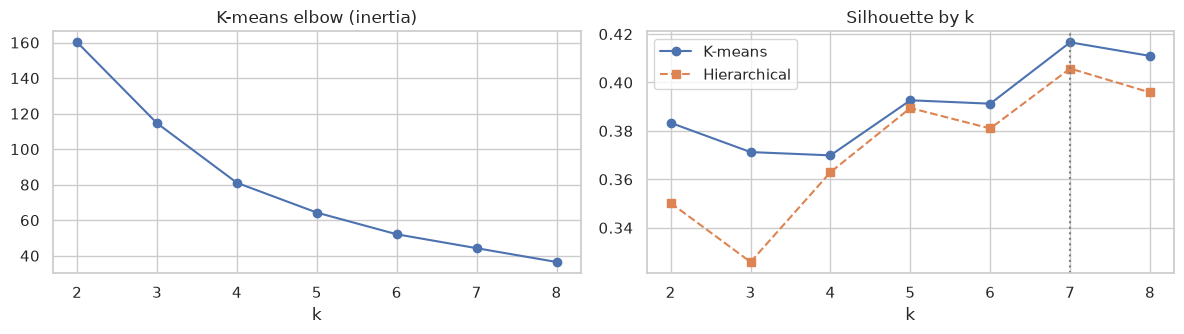

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,160.130,0.383,0.981,113.393
3,114.564,0.371,0.898,106.728
4,81.029,0.370,0.828,119.200
5,64.266,0.393,0.777,120.978
6,52.063,0.391,0.812,125.076
7,44.239,0.417,0.688,125.815
8,36.465,0.411,0.701,134.020


In [10]:
km_scores = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    km_scores.append({"k": k, "inertia": km.inertia_, **score_labels(X, km.labels_)})
km_scores = pd.DataFrame(km_scores).set_index("k")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(km_scores.index, km_scores.inertia, "o-"); ax[0].set_title("K-means elbow (inertia)")
ax[1].plot(km_scores.index, km_scores.silhouette, "o-", label="K-means")
ax[1].plot(hc_scores.index, hc_scores.silhouette, "s--", label="Hierarchical")
ax[1].axvline(BEST_K, color="grey", ls=":"); ax[1].legend(); ax[1].set_title("Silhouette by k")
for a in ax: a.set_xlabel("k")
plt.tight_layout(); plt.show()
km_scores.round(3)

### 7b · Final K-means model

K-means k=7: silhouette=0.417, davies_bouldin=0.688, calinski_harabasz=125.815


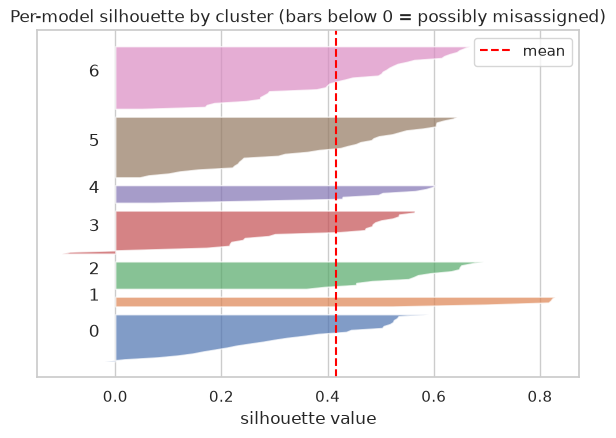

models with negative silhouette: 3 of 144


In [11]:
kmeans = KMeans(n_clusters=BEST_K, n_init=50, random_state=SEED).fit(X)
km_labels = kmeans.labels_
final_scores = score_labels(X, km_labels)
print(f"K-means k={BEST_K}: " + ", ".join(f"{k}={v:.3f}" for k, v in final_scores.items()))

sil = silhouette_samples(X, km_labels)
fig, ax = plt.subplots(figsize=(7, 4.5)); y = 0
for c in range(BEST_K):
    s = np.sort(sil[km_labels == c]); ax.fill_betweenx(np.arange(y, y + len(s)), 0, s, alpha=.7)
    ax.text(-0.05, y + len(s) / 2, str(c)); y += len(s) + 3
ax.axvline(final_scores["silhouette"], color="red", ls="--", label="mean")
ax.set_xlabel("silhouette value"); ax.set_yticks([]); ax.legend()
ax.set_title("Per-model silhouette by cluster (bars below 0 = possibly misassigned)"); plt.show()
print("models with negative silhouette:", int((sil < 0).sum()), "of", len(sil))

**Reading the silhouette plot:** each band is one cluster, and each horizontal line is one model. Wide bands to the right of the red line mean well-separated clusters. Values below 0 are borderline models that sit between two tiers. A few are normal, because real prices form a continuum.

## Step 8 · Are the tiers real? Agreement and stability
Clusters are only useful if they are **not an accident** of the algorithm, the random seed, or the particular sample of models. We use the **Adjusted Rand Index (ARI)**: 1 = identical partitions, 0 = no better than chance.

1. **Method agreement:** hierarchical (Step 6) vs K-means (Step 7) labels.
2. **Seed stability:** K-means re-run with 50 different seeds.
3. **Sample stability (bootstrap):** 50 random 80 % subsamples. Each time we refit K-means and compare with the full-data labels of the same models.

As a rule of thumb, ARI > 0.8 means very stable and 0.6–0.8 means reasonably stable.

In [12]:
ari_methods = adjusted_rand_score(hc_labels, km_labels)
ari_seeds = [adjusted_rand_score(km_labels, KMeans(n_clusters=BEST_K, n_init=10, random_state=s).fit_predict(X))
             for s in range(50)]
rng = np.random.default_rng(SEED); ari_boot = []
for _ in range(50):
    idx = rng.choice(len(X), size=int(.8 * len(X)), replace=False)
    sub = KMeans(n_clusters=BEST_K, n_init=10, random_state=SEED).fit_predict(X[idx])
    ari_boot.append(adjusted_rand_score(km_labels[idx], sub))

stab = pd.DataFrame({"check": ["Hierarchical vs K-means", "K-means across 50 seeds", "Bootstrap 80% × 50"],
                     "ARI_mean": [ari_methods, np.mean(ari_seeds), np.mean(ari_boot)],
                     "ARI_min": [ari_methods, np.min(ari_seeds), np.min(ari_boot)]}).round(3)
display(stab)
display(pd.crosstab(pd.Series(hc_labels, name="hierarchical"), pd.Series(km_labels, name="k-means")))

,check,ARI_mean,ARI_min
0,Hierarchical vs K-means,0.903,0.903
1,K-means across 50 seeds,0.793,0.576
2,Bootstrap 80% × 50,0.721,0.500


k-means,0,1,2,3,4,5,6
hierarchical,,,,,,,
0,0,0,0,22,0,0,0
1,1,0,0,1,0,0,32
2,24,0,0,0,0,2,0
3,0,0,0,0,0,30,1
4,0,0,0,0,10,0,0
5,0,0,15,0,0,0,0
6,0,6,0,0,0,0,0


**Reading the results:** the cross-table shows how the two methods' clusters correspond. Most models should fall on one cell per row. Off-diagonal counts are the borderline models from the silhouette plot.

## Step 9 · Profile and name the tiers
A cluster number means nothing to a company, so we turn each cluster into a **named tier**. We describe each one by its median price, median performance, size, share of open-weight models, main labs and example models. The name comes from where the tier's centre sits relative to the whole market:
- **price level:** Low / Mid / High, by the tertile of the market's log price
- **performance level:** Low / Mid / High, by the tertile of the market's performance

We also compute a **value score** = performance ÷ log-scaled cost. Higher means more benchmark performance per dollar.

In [13]:
pop["cluster"] = km_labels
p_cut = pop.log_price.quantile([1/3, 2/3]).values
q_cut = pop.performance.quantile([1/3, 2/3]).values
level = lambda v, cuts: ["Low", "Mid", "High"][int(np.searchsorted(cuts, v))]

prof = pop.groupby("cluster").agg(
    n=("model_id", "size"),
    median_price=("blended_price", "median"),
    price_q1=("blended_price", lambda s: s.quantile(.25)), price_q3=("blended_price", lambda s: s.quantile(.75)),
    median_perf=("performance", "median"),
    perf_q1=("performance", lambda s: s.quantile(.25)), perf_q3=("performance", lambda s: s.quantile(.75)),
    median_log_price=("log_price", "median"),
    open_weights_share=("open_weights", "mean"), median_tests=("n_tests", "median"))
prof["tier"] = [f"{level(r.median_log_price, p_cut)}-price / {level(r.median_perf, q_cut)}-performance"
                for r in prof.itertuples()]
prof = prof.sort_values("median_price")
prof["tier_id"] = range(1, len(prof) + 1)                      # 1 = cheapest tier
pop["tier_id"] = pop.cluster.map(prof.tier_id)
pop["tier"] = pop.cluster.map(prof.tier)

# value: performance per order-of-magnitude of price (shifted so the cheapest model's cost term is 1)
pop["value_score"] = pop.performance / (pop.log_price - pop.log_price.min() + 1)
prof["median_value"] = pop.groupby("cluster").value_score.median()
prof["top_labs"] = pop.groupby("cluster").lab.agg(lambda s: ", ".join(s.value_counts().head(3).index))
prof["examples"] = pop.sort_values("n_tests", ascending=False).groupby("cluster").model_name.agg(
    lambda s: ", ".join(s.head(4)))
show = prof.set_index("tier_id")[["tier", "n", "median_price", "price_q1", "price_q3", "median_perf",
                                  "perf_q1", "perf_q3", "median_value", "open_weights_share",
                                  "median_tests", "top_labs", "examples"]]
show.round(3)

,tier,n,median_price,price_q1,price_q3,median_perf,perf_q1,perf_q3,median_value,open_weights_share,median_tests,top_labs,examples
tier_id,,,,,,,,,,,,,
1,Low-price / Low-performance,6,0.163,0.147,0.175,0.031,0.008,0.035,0.024,0.500,1.5,"openai, nvidia, zhipuai","Nemotron 3.5 Lightning 30B A3B, Gemini 2.5 Fla..."
2,Low-price / High-performance,10,0.250,0.181,0.308,0.757,0.681,0.872,0.500,0.900,3.0,"deepseek, xiaomi, stepfun","MiMo-V2.6-Pro, MiMo-V2.6-Flash, GLM-5.3-Flash,..."
3,Low-price / Mid-performance,15,0.275,0.203,0.407,0.374,0.353,0.447,0.254,0.933,3.0,"alibaba, deepseek, tencent","Step 3.7 Flash, GPT-5.6 Luna, DeepSeek V4 Flas..."
4,Mid-price / Low-performance,32,0.802,0.626,1.088,0.173,0.108,0.273,0.089,0.594,2.5,"alibaba, openai, meta","MiMo-V2.5-Pro, Nemotron 3 Ultra 550B A55B, Qwe..."
5,Mid-price / Mid-performance,33,1.925,1.500,3.000,0.576,0.540,0.638,0.247,0.485,4.0,"google, zhipuai, alibaba","GPT-5.4, Gemini 3.5 Flash, GPT-5.6 Terra, Qwen..."
6,High-price / Mid-performance,25,4.500,3.500,6.000,0.340,0.214,0.412,0.122,0.080,2.0,"openai, anthropic, xai","Gemini 3.1 Pro Preview, Claude Sonnet 4.6, Cla..."
7,High-price / High-performance,23,10.000,5.406,20.000,0.803,0.710,0.861,0.260,0.043,5.0,"openai, anthropic, moonshotai","GPT-5.5, Claude Opus 4.7, GPT-6 Astra, GPT-5.6..."


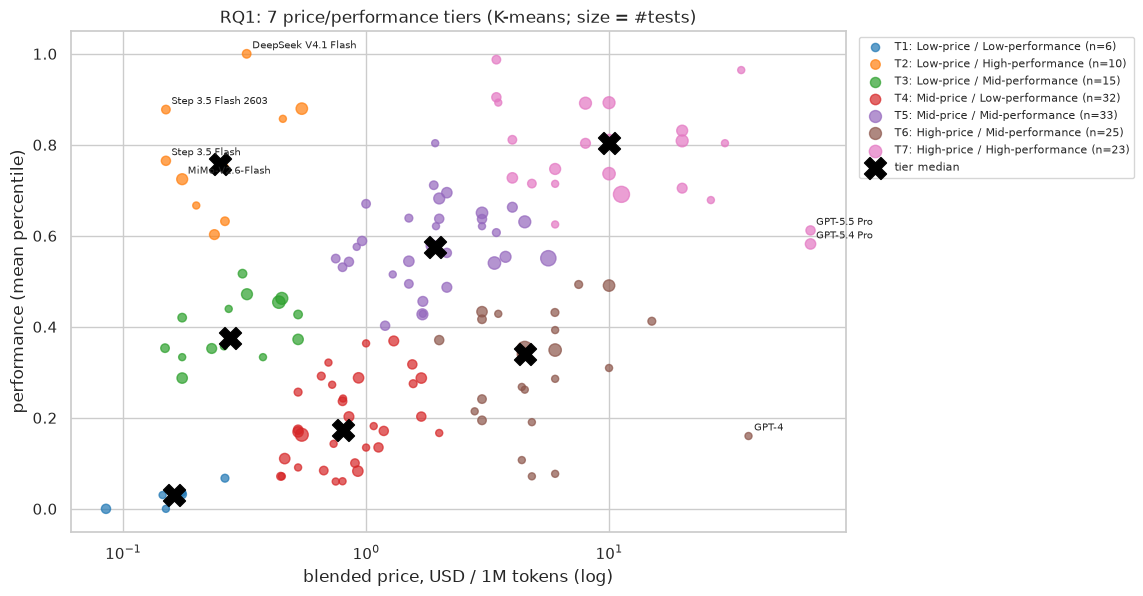

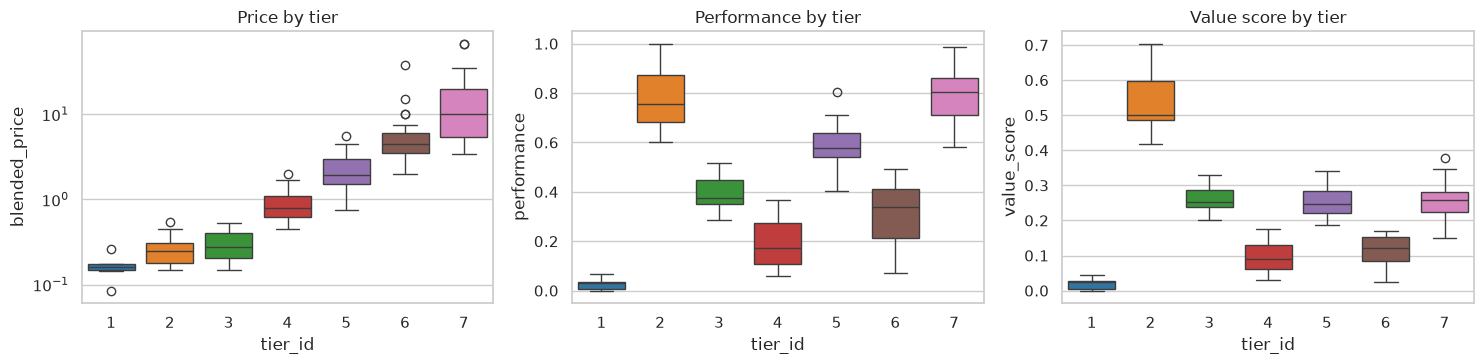

In [14]:
pal = dict(zip(sorted(pop.tier_id.unique()), sns.color_palette("tab10", BEST_K)))
fig, ax = plt.subplots(figsize=(10, 6.5))
for t, d in pop.groupby("tier_id"):
    ax.scatter(d.blended_price, d.performance, s=20 + 6 * d.n_tests, alpha=.7, color=pal[t],
               label=f"T{t}: {prof.set_index('tier_id').tier[t]} (n={len(d)})")
cent = pop.groupby("tier_id")[["blended_price", "performance"]].median()
ax.scatter(cent.blended_price, cent.performance, marker="X", s=250, c="black", label="tier median")
for _, r in pd.concat([pop.nlargest(4, "value_score"), pop.nlargest(3, "blended_price")]).iterrows():
    ax.annotate(r.model_name, (r.blended_price, r.performance), fontsize=7, xytext=(4, 4),
                textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("blended price, USD / 1M tokens (log)")
ax.set_ylabel("performance (mean percentile)")
ax.set_title(f"RQ1: {BEST_K} price/performance tiers (K-means; size = #tests)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1)); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.boxplot(data=pop, x="tier_id", y="blended_price", hue="tier_id", palette=pal, legend=False, ax=ax[0])
ax[0].set_yscale("log"); ax[0].set_title("Price by tier")
sns.boxplot(data=pop, x="tier_id", y="performance", hue="tier_id", palette=pal, legend=False, ax=ax[1])
ax[1].set_title("Performance by tier")
sns.boxplot(data=pop, x="tier_id", y="value_score", hue="tier_id", palette=pal, legend=False, ax=ax[2])
ax[2].set_title("Value score by tier")
plt.tight_layout(); plt.show()

## Step 10 · Test H1 statistically
H1 has two parts. We test both with **non-parametric** tests, because prices and percentiles are not normally distributed and the tiers differ in size.

**H1a: at least 3 *distinct* tiers.**
- k ≥ 3 (Step 6), **and**
- the tiers really differ in price and in performance: a **Kruskal–Wallis** test across tiers, p < 0.05.

**H1b: a tier with a high price but no matching benchmark advantage.**
For every pair of tiers (A, B) where A is **significantly more expensive** than B (one-sided Mann–Whitney, p < 0.05), we test whether A also **performs significantly better** than B. If at least one expensive tier does *not* significantly outperform a cheaper tier, H1b is supported. Many pairs are tested at once, so p-values are corrected with the **Holm** method to avoid false discoveries.

In [15]:
def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p)
    adj = np.empty(m); run = 0
    for i, j in enumerate(order):
        run = max(run, (m - i) * p[j]); adj[j] = min(run, 1)
    return adj

groups = [d for _, d in pop.groupby("tier_id")]
kw_price, kw_perf = kruskal(*[g.log_price for g in groups]), kruskal(*[g.performance for g in groups])
print(f"Kruskal–Wallis price:       H={kw_price.statistic:.1f}, p={kw_price.pvalue:.2e}")
print(f"Kruskal–Wallis performance: H={kw_perf.statistic:.1f}, p={kw_perf.pvalue:.2e}")

rows = []
tiers = sorted(pop.tier_id.unique())
for a in tiers:
    for b_ in tiers:
        if a == b_: continue
        A, B = pop[pop.tier_id == a], pop[pop.tier_id == b_]
        rows.append({"A": a, "B": b_,
                     "price_ratio": A.blended_price.median() / B.blended_price.median(),
                     "p_price": mannwhitneyu(A.log_price, B.log_price, alternative="greater").pvalue,
                     "perf_diff": A.performance.median() - B.performance.median(),
                     "p_perf": mannwhitneyu(A.performance, B.performance, alternative="greater").pvalue})
pairs = pd.DataFrame(rows)
pairs["p_price_holm"] = holm(pairs.p_price); pairs["p_perf_holm"] = holm(pairs.p_perf)
pairs = pairs[pairs.p_price_holm < 0.05].copy()               # keep pairs where A is significantly pricier
pairs["A_outperforms_B"] = pairs.p_perf_holm < 0.05
pairs["tier_A"] = pairs.A.map(prof.set_index("tier_id").tier)
pairs["tier_B"] = pairs.B.map(prof.set_index("tier_id").tier)
pairs.round(4)

Kruskal–Wallis price:       H=125.6, p=1.09e-24
Kruskal–Wallis performance: H=124.0, p=2.36e-24


,A,B,price_ratio,p_price,perf_diff,p_perf,p_price_holm,p_perf_holm,A_outperforms_B,tier_A,tier_B
18,4,1,4.9346,0.0001,0.1416,0.0001,0.0018,0.0026,True,Mid-price / Low-performance,Low-price / Low-performance
19,4,2,3.2075,0.0000,-0.5849,1.0000,0.0001,1.0000,False,Mid-price / Low-performance,Low-price / High-performance
20,4,3,2.9159,0.0000,-0.2019,1.0000,0.0000,1.0000,False,Mid-price / Low-performance,Low-price / Mid-performance
24,5,1,11.8462,0.0001,0.5447,0.0001,0.0018,0.0020,True,Mid-price / Mid-performance,Low-price / Low-performance
25,5,2,7.7000,0.0000,-0.1817,0.9999,0.0000,1.0000,False,Mid-price / Mid-performance,Low-price / High-performance
26,5,3,7.0000,0.0000,0.2013,0.0000,0.0000,0.0000,True,Mid-price / Mid-performance,Low-price / Mid-performance
27,5,4,2.4006,0.0000,0.4032,0.0000,0.0000,0.0000,True,Mid-price / Mid-performance,Mid-price / Low-performance
30,6,1,27.6923,0.0001,0.3087,0.0001,0.0025,0.0027,True,High-price / Mid-performance,Low-price / Low-performance
31,6,2,18.0000,0.0000,-0.4177,1.0000,0.0001,1.0000,False,High-price / Mid-performance,Low-price / High-performance
32,6,3,16.3636,0.0000,-0.0347,0.9925,0.0000,1.0000,False,High-price / Mid-performance,Low-price / Mid-performance


In [16]:
h1a = (BEST_K >= 3) and kw_price.pvalue < .05 and kw_perf.pvalue < .05
overpriced = pairs[~pairs.A_outperforms_B]
h1b = len(overpriced) > 0

print(f"H1a  ≥3 distinct tiers:           k={BEST_K}, KW p(price)={kw_price.pvalue:.1e}, "
      f"KW p(perf)={kw_perf.pvalue:.1e}  →  {'SUPPORTED' if h1a else 'NOT supported'}")
print(f"H1b  pricier tier w/o advantage:  {len(overpriced)} of {len(pairs)} 'pricier' pairs  →  "
      f"{'SUPPORTED' if h1b else 'NOT supported'}")
for r in overpriced.itertuples():
    print(f"       T{r.A} ({r.tier_A}) is {r.price_ratio:.1f}× pricier than T{r.B} ({r.tier_B}) "
          f"but not significantly better (Holm p={r.p_perf_holm:.3f}, median perf diff {r.perf_diff:+.2f})")
print(f"\nH1 overall: {'SUPPORTED' if h1a and h1b else 'NOT (fully) supported'}")

H1a  ≥3 distinct tiers:           k=7, KW p(price)=1.1e-24, KW p(perf)=2.4e-24  →  SUPPORTED
H1b  pricier tier w/o advantage:  7 of 17 'pricier' pairs  →  SUPPORTED
       T4 (Mid-price / Low-performance) is 3.2× pricier than T2 (Low-price / High-performance) but not significantly better (Holm p=1.000, median perf diff -0.58)
       T4 (Mid-price / Low-performance) is 2.9× pricier than T3 (Low-price / Mid-performance) but not significantly better (Holm p=1.000, median perf diff -0.20)
       T5 (Mid-price / Mid-performance) is 7.7× pricier than T2 (Low-price / High-performance) but not significantly better (Holm p=1.000, median perf diff -0.18)
       T6 (High-price / Mid-performance) is 18.0× pricier than T2 (Low-price / High-performance) but not significantly better (Holm p=1.000, median perf diff -0.42)
       T6 (High-price / Mid-performance) is 16.4× pricier than T3 (Low-price / Mid-performance) but not significantly better (Holm p=1.000, median perf diff -0.03)
       T6 (High-pr

## Step 11 · Sensitivity check: do the tiers hold for better-measured models?
About a third of the models have a performance score based on a **single test**, which makes those scores noisy. We repeat the whole pipeline (percentiles → features → hierarchical k-choice → K-means) using only models with **≥ 2 tests**, and compare:
- Is the same k chosen?
- Do the models that appear in both runs land in the same tiers (ARI)?

In [17]:
def run_pipeline(b_all, priced, min_tests):
    bb = b_all.copy()
    cov = bb.groupby("test").model_id.nunique()
    bb = bb[bb.test.isin(cov[cov >= MIN_MODELS_PER_TEST].index)]
    per = bb.groupby("model_id").size(); bb = bb[bb.model_id.isin(per[per >= min_tests].index)]
    cov = bb.groupby("test").model_id.nunique(); bb = bb[bb.test.isin(cov[cov >= MIN_MODELS_PER_TEST].index)]
    bb["pctl"] = percentile_within_test(bb)
    p = priced.merge(bb.groupby("model_id").agg(performance=("pctl", "mean"), n_tests=("pctl", "size")),
                     left_on="model_id", right_index=True)
    p = p[p.n_tests >= min_tests]
    p["log_price"] = np.log10((3 * p.median_input_price_per_1m + p.median_output_price_per_1m) / 4)
    Xs = StandardScaler().fit_transform(p[FEATURES])
    sc = pd.DataFrame({k: score_labels(Xs, AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Xs))
                       for k in K_RANGE}).T
    rk = pd.concat([sc.silhouette.rank(ascending=False), sc.davies_bouldin.rank(),
                    sc.calinski_harabasz.rank(ascending=False)], axis=1).mean(axis=1)
    k = int(pd.DataFrame({"r": rk, "s": sc.silhouette}).sort_values(["r", "s"], ascending=[True, False]).index[0])
    lab = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit_predict(Xs)
    return p.assign(cluster_s=lab), k, sc.silhouette[k]

b_all = bench[bench.higher_is_better & bench.model_id.isin(priced.model_id)].assign(
    test=lambda d: d.benchmark_clean + " [" + d.metric_clean + "]")
sens, k_s, sil_s = run_pipeline(b_all, priced, min_tests=2)
both = pop.merge(sens[["model_id", "cluster_s"]], on="model_id")
ari_sens = adjusted_rand_score(both.cluster, both.cluster_s)
print(f"Main run:      n={len(pop)}, k={BEST_K}, silhouette={final_scores['silhouette']:.3f}")
print(f"≥2-test run:   n={len(sens)}, k={k_s}, silhouette={sil_s:.3f}")
print(f"ARI on the {len(both)} shared models: {ari_sens:.3f}")

Main run:      n=144, k=7, silhouette=0.417
≥2-test run:   n=97, k=7, silhouette=0.389
ARI on the 97 shared models: 0.566


## Step 12 · Save the tier labels
The tiers become the **target labels for RQ2**: can a model's tier be predicted from its features (provider, open/closed, capabilities)? They are also an input for RQ4.

In [18]:
out = pop[["model_id", "model_name", "lab", "open_weights", "blended_price", "log_price",
           "performance", "n_tests", "value_score", "cluster", "tier_id", "tier"]].assign(
           hc_cluster=hc_labels).sort_values(["tier_id", "blended_price"])
out.to_csv(os.path.join(OUT_DIR, "rq1_tiers.csv"), index=False)
prof.to_csv(os.path.join(OUT_DIR, "rq1_tier_profiles.csv"))
print("saved rq1_tiers.csv", out.shape, "and rq1_tier_profiles.csv")
if IN_COLAB:
    files.download("rq1_tiers.csv"); files.download("rq1_tier_profiles.csv")

saved rq1_tiers.csv (144, 13) and rq1_tier_profiles.csv


## Step 13 · Conclusion

In [19]:
print(f"Models clustered: {len(pop)} priced text LLMs, {len(good_tests)} benchmark tests")
print(f"Best k (hierarchical, voting on 3 metrics): {BEST_K}")
print(f"K-means: silhouette={final_scores['silhouette']:.3f}, DB={final_scores['davies_bouldin']:.3f}")
print(f"Agreement HC vs K-means ARI={ari_methods:.2f}; seed ARI={np.mean(ari_seeds):.2f}; "
      f"bootstrap ARI={np.mean(ari_boot):.2f}; ≥2-test re-run k={k_s}, ARI={ari_sens:.2f}")
print()
print(show[["tier", "n", "median_price", "median_perf", "median_value"]].round(3).to_string())
print(f"\nH1a (≥3 distinct tiers): {'SUPPORTED' if h1a else 'NOT supported'}")
print(f"H1b (pricey tier without benchmark advantage): {'SUPPORTED' if h1b else 'NOT supported'}")

Models clustered: 144 priced text LLMs, 43 benchmark tests
Best k (hierarchical, voting on 3 metrics): 7
K-means: silhouette=0.417, DB=0.688
Agreement HC vs K-means ARI=0.90; seed ARI=0.79; bootstrap ARI=0.72; ≥2-test re-run k=7, ARI=0.57

                                  tier   n  median_price  median_perf  median_value
tier_id                                                                            
1          Low-price / Low-performance   6         0.163        0.031         0.024
2         Low-price / High-performance  10         0.250        0.757         0.500
3          Low-price / Mid-performance  15         0.275        0.374         0.254
4          Mid-price / Low-performance  32         0.802        0.173         0.089
5          Mid-price / Mid-performance  33         1.925        0.576         0.247
6         High-price / Mid-performance  25         4.500        0.340         0.122
7        High-price / High-performance  23        10.000        0.803         0.260

H1a

### Answer to RQ1
**The 2026 LLM API market forms 7 price/performance tiers** (144 priced text LLMs, 43 benchmark tests). They are listed from cheapest to most expensive (median blended price per 1M tokens, median performance percentile):

| Tier | Name | n | Price | Perf. | Typical members |
|---|---|---|---|---|---|
| T1 | Low-price / Low-performance | 6 | $0.16 | 0.03 | small and "lite" models (GPT-4o mini, Gemini 2.5 Flash-Lite, Devstral Small) |
| T2 | **Low-price / High-performance** | 10 | $0.25 | 0.76 | Chinese open-weight "flash" models (DeepSeek, MiMo, Step, GLM-Flash), 90 % open-weight |
| T3 | Low-price / Mid-performance | 15 | $0.28 | 0.37 | budget flash models (Qwen Flash, DeepSeek V4 Flash, Step 3.7 Flash) |
| T4 | Mid-price / Low-performance | 32 | $0.80 | 0.17 | mid-size and "mini" models (GPT-5.4 mini, Qwen3.8 27B, Nemotron Ultra) |
| T5 | Mid-price / Mid-performance | 33 | $1.93 | 0.58 | mainstream workhorses (GPT-5.4, Gemini 3.5 Flash, Qwen3.8 Max Preview) |
| T6 | **High-price / Mid-performance** | 25 | $4.50 | 0.34 | older or "previous-gen" flagships (GPT-4o, GPT-4.1, Grok 4.6, Command A, Claude 4.6) |
| T7 | High-price / High-performance | 23 | $10.00 | 0.80 | frontier models (GPT-5.6 Sol, Claude Opus 5, GPT-6 Sol, Kimi K3) |

### Verdict on H1: **supported**
- **H1a (≥ 3 distinct tiers): supported.** Hierarchical clustering chose k = 7 by voting on silhouette, Davies–Bouldin and Calinski–Harabasz, and K-means independently scores best at k = 7 as well (silhouette 0.417). The tiers differ significantly in both price and performance (Kruskal–Wallis p ≈ 10⁻²⁴ for each).
- **H1b (a high-price tier without a matching benchmark advantage): supported.** **T6 costs 2.3× more than T5 and 18× more than T2, yet performs *worse* than both** (median percentile 0.34 vs 0.58 and 0.76). Even the frontier tier T7 is **not significantly better than the cheap T2** (Holm-corrected p = 1.0), despite a 40× higher median price.

**Practical meaning:** price is a poor proxy for benchmark performance. A company paying T6 prices would get better scores from a T5 model for less than half the cost. For many tasks, a T2 model matches T7 at about 1/40 of the price.

### How much to trust the tiers
| Check | Result | Reading |
|---|---|---|
| Hierarchical vs K-means agreement | ARI 0.90 | both methods find essentially the same tiers |
| K-means across 50 seeds | ARI 0.79 (min 0.58) | stable, with some borderline models moving between neighbouring tiers |
| Bootstrap 80 % × 50 | ARI 0.72 (min 0.50) | reasonably stable |
| Only models with ≥ 2 tests (n = 97) | k = 7 again, ARI 0.57 | the *number* of tiers holds, but individual memberships shift |
| Negative silhouette | 3 of 144 | very few misfits |

### Limitations (state these in the report)
1. **The structure is a continuum, not sharp groups.** The silhouette ranges only 0.33–0.42 across all k, and the biggest dendrogram gap is at k = 2. Seven tiers is the best *description*, but the borders between neighbouring tiers are soft.
2. **Percentiles are relative to each test's participants, and that introduces an era bias.** Older models (o3, Gemini 2.5 Pro, Claude Sonnet 3.7) were mostly scored on older benchmarks against their own generation, so they reach high percentiles. Recent flagships (Claude Opus 4.6, Gemini 3.1 Pro) are compared with today's frontier and score lower. This partly explains why T6 mixes truly outdated models (GPT-4o, GPT-4.1) with recent flagships. Possible fixes: restrict to models released in the last 12 months, or keep only tests that cover several model generations.
3. **Sparse evidence:** 47 models rest on a single test. The ≥ 2-test re-run keeps k = 7, but memberships change (ARI 0.57).
4. **Price is the median across providers at the snapshot date.** A model's cheapest offer can be much lower, and prices change over time (that is RQ3).

**Output:** `rq1_tiers.csv` (tier label for each model) is the target variable for **RQ2**: can a model's tier be predicted from provider, open/closed status and capability features?